# 图像编码熊猫实验｜教师版

对应冻结课件 `1-2-3-image-encoding-panda-v4-20261011.pptx`（85页，2026-10-11）。

本文件含教师答案与操作说明，仅用于备课和教师私下查看。课堂切换时投影学生版demo-lab-student.ipynb，依次运行当前单元；不要把本教师版滚动区投影。完整实验适合另加一课时或课后，不是45分钟课堂的新增必做任务。短演示可选D3、D4、D10，具体时点与跳过规则见README。

## 准备｜打开原图，不运行后面的实验

从课程目录启动JupyterLab，选择已安装NumPy、Pillow、Matplotlib的Python内核。依次运行单元；不要使用“Run All”。课堂由教师操作，学生先写预测再观察。学生版用于加课时或课后练习，代码结果只有运行后才出现。

本实验处理已有JPEG的解码像素，不是对真实光线进行相机拍摄。图像区域固定为(x,y,w,h)=(280,100,288,288)，坐标从0开始；矩阵的行列说明从1开始。

**教师操作与追问**

备课时先执行本单元。若启动或取数超过30秒，返回冻结PPTX中对应证据页，或打开fallback/teacher-evidence.html。本页只检查环境，不投影教师版全文。图像为用户提供素材，来源与变换见README。

In [1]:
#| label: setup
from pathlib import Path
import numpy as np
from IPython.display import display
from demos import panda_lab as lab
source = lab.load_source()
print("素材就绪；原图尺寸：", source.size)

素材就绪；原图尺寸： (886, 1000)


## D1｜采样后，每格的颜色怎样记录？（Q3–Q6，6–14页）

固定熊猫区域，先划成8×8格。每格保留平均RGB。只能从四色表中选一色时，第2行第3列会怎样改变？

先指认：网格决定哪些位置？平均色与有限代表色是否总相同？

**教师操作与追问**

操作：先显示区域与未量化均值，再让学生指第2行第3列。平均值用于距离计算时不取整；显示近似色才四舍五入。让学生说出“取样位置”和“可选颜色”两件事后，运行下一单元。


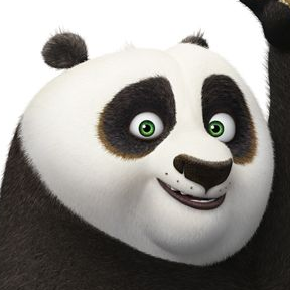
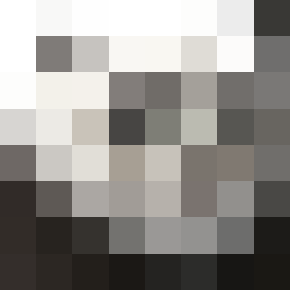

编号,代表色,RGB,码字
0,,"(36, 33, 27)",—
1,,"(119, 118, 110)",—
2,,"(188, 187, 179)",—
3,,"(242, 240, 230)",—


In [2]:
#| label: d1
means8 = lab.sample_blocks(8)
lab.show_images([
    ("原图同一区域", source.crop((280, 100, 568, 388))),
    ("每格的平均RGB", lab.Image.fromarray(np.rint(means8).astype(np.uint8))),
])
lab.show_palette(4)

**记录**：预测________；观察证据________；解释／修正________。

## D1证据｜用相同规则处理64个样本

先在四色表中作选择，再运行。比较第2行第3列的平均RGB、代表色编号及代表色RGB。

**教师操作与追问**

让学生用图和数值区分平均色、量化等级。规则是与调色板颜色的三通道平方距离最小；不要求高中学生推导距离公式。颜色变成有限选择是量化，稍后编号写成bit才是编码。


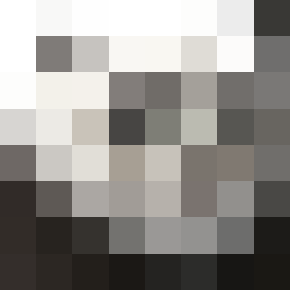
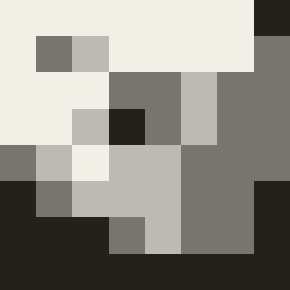

样本位置,平均RGB（显示近似）,代表色编号,代表色RGB
第2行，第3列,"(198.11, 195.15, 190.75)",2,"(188, 187, 179)"


In [3]:
#| label: d1-reveal
coarse = lab.quantize(means8, 4)
lab.show_images([("平均RGB", lab.Image.fromarray(np.rint(means8).astype(np.uint8))),
                 ("限制为4色", lab.rgb_image(coarse))])
row, column = 2, 3
value = means8[row - 1, column - 1]
index = int(coarse[row - 1, column - 1])
lab.show_table(["样本位置", "平均RGB（显示近似）", "代表色编号", "代表色RGB"],
               [(f"第{row}行，第{column}列", tuple(np.round(value, 2)), index, tuple(lab.PALETTE[index]))])

**记录**：预测________；观察证据________；解释／修正________。

## D2｜怎样编码？每像素用几bit？（Q5–Q6，11–14页）

先用四色表写出8×8矩阵第四行的码字。每个码字长度相同，不能省掉前导0。先看颜色编号，独立写出二进制。

**教师操作与追问**

先独立写20秒，再按码表核对。第四行为33201211；不要提前读出。若把11看成两个像素，回指“每格一个2位码字”。

In [4]:
#| label: d2
coarse = lab.quantize(lab.sample_blocks(8), 4)
lab.show_row(coarse[3])

颜色,,,,,,,,
位置,1,2,3,4,5,6,7,8
编号,3,3,2,0,1,2,1,1


**记录**：预测________；观察证据________；解释／修正________。

## D2证据｜编号换成固定长度码字

填写后运行。编码是否改变了已确定的代表色？

**教师操作与追问**

第四行11 11 10 00 01 10 01 01。编码改变表示形式，没有再次选色。整幅64个像素各2bit；此处不急着给全图字节数，留给D6。

In [5]:
#| label: d2-reveal
bits_per_pixel = 2
lab.show_row(coarse[3], bits_per_pixel)
coarse_words = lab.encode(coarse, bits_per_pixel)
print("整图像素数：", coarse.size, "；固定码字数：", len(coarse_words))

颜色,,,,,,,,
位置,1,2,3,4,5,6,7,8
编号,3,3,2,0,1,2,1,1
码字,11,11,10,00,01,10,01,01


整图像素数： 64 ；固定码字数： 64


**记录**：预测________；观察证据________；解释／修正________。

## T1｜先总结，再随课件更新知识树（15–18页）

用刚才的证据分别说明：确定位置、选择有限颜色、写成码字，各做了什么？请写三句话及对应证据。不要只写三个名词。

我的总结：________；证据：________。

**教师操作与追问**

收集学生解释后，回到PPTX15页，让学生总结。再按16、17、18页逐枝揭示采样、量化、编码。此处不展示数据量、RGB、解码或最终树。预算20–30秒学生总结；保留先总结后揭示的顺序。

## D3｜怎样让数字熊猫更接近原图？（Q7，19–20页）

只把采样从8×8改为16×16，保留同一区域和四色表。预测：位置数、每个码字长度分别会怎样变化？

**教师操作与追问**

只改变采样数量。强调16×16来自原区域重新分块，不是把8×8结果放大。用轮廓、局部边界和256个位置说明；不能宣称任意图像加采样必然具有主观视觉改善。


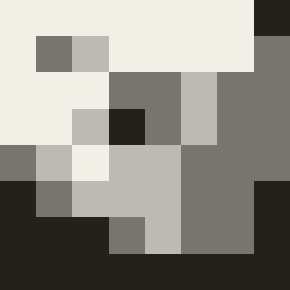
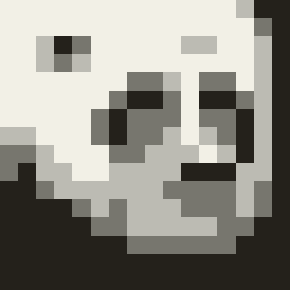

In [6]:
#| label: d3
left_grid, right_grid, color_levels = 8, 16, 4
lab.show_sampling(left_grid, right_grid, color_levels)

**记录**：预测________；观察证据________；解释／修正________。

## D3读码｜红框里的8个像素怎样编码？（Q7-read，21–22页）

使用16×16、四色结果；取第6行第5–12列，从左到右写出8个2位码字。先独立填写，不运行后面的核对单元。

**教师操作与追问**

第6行对应Python索引5，第5列对应索引4；切片右端12不包含第13列。先看颜色编号，完成后才运行核对。

In [7]:
#| label: d3-read
fine = lab.quantize(lab.sample_blocks(16), 4)
selected = fine[5, 4:12]
lab.show_row(selected)

颜色,,,,,,,,
位置,1,2,3,4,5,6,7,8
编号,3,3,1,0,0,1,3,0


**记录**：预测________；观察证据________；解释／修正________。

## D3读码核对｜保留前导0

写好后运行；说明这里是一行的一段，还是整幅图。

**教师操作与追问**

对应11 11 01 00 00 01 11 00，共16bit。选段来自第6行，不是D2的8×8第四行。Q18稍后把同一段当作完整小图，只有到58页才能讨论重新分行。

In [8]:
#| label: d3-read-reveal
lab.show_row(selected, 2)
selected_words = lab.encode(selected, 2)
print("这一段共", len(selected_words) * 2, "bit")

颜色,,,,,,,,
位置,1,2,3,4,5,6,7,8
编号,3,3,1,0,0,1,3,0
码字,11,11,01,00,00,01,11,00


这一段共 16 bit


**记录**：预测________；观察证据________；解释／修正________。

## D4｜格子不变，颜色还能怎样改进？（Q9，25–29页）

保持16×16样本不变，四色表保留全部原颜色，再加两色。预测：变化的是样本位置还是可选颜色？六色还可用2bit吗？

**教师操作与追问**

学生先预测再运行。第一组的四种颜色在第二组全部保留，变化只在代表色选择。先观察选色，再由6种状态推导最少3bit；不要因为编号0–3没变就沿用旧2位码字。


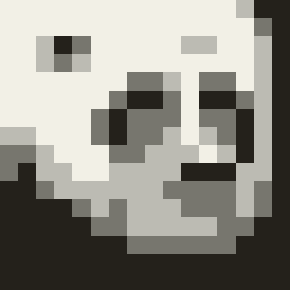
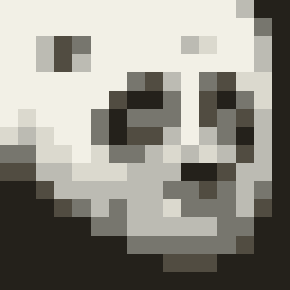

编号,代表色,RGB,码字
0,,"(36, 33, 27)",—
1,,"(119, 118, 110)",—
2,,"(188, 187, 179)",—
3,,"(242, 240, 230)",—
4,,"(81, 76, 65)",—
5,,"(219, 217, 206)",—


In [9]:
#| label: d4
color_levels = 6
lab.show_quantization(color_levels)
lab.show_palette(color_levels)

**记录**：预测________；观察证据________；解释／修正________。

## D4局部证据｜同一个样本的选择改变了吗？（27页）

取第10行第13列。先指出两次操作中保持不变的值，再运行核对。

**教师操作与追问**

平均值约(78.25,73.31,68.40)；四色选0，六色选4。数值和编号为投影色差提供替代证据。仅说明此样本及既定距离规则；不把RGB距离当作视觉质量评分。

In [10]:
#| label: d4-probe
means16 = lab.sample_blocks(16)
four = lab.quantize(means16, 4)
six = lab.quantize(means16, 6)
r, c = 10 - 1, 13 - 1
lab.show_table(["可选颜色数", "同一样本平均RGB", "代表色编号", "代表色RGB"],
    [(n, tuple(np.round(means16[r, c], 2)), int(a[r, c]), tuple(lab.PALETTE[a[r, c]]))
     for n, a in [(4, four), (6, six)]])

可选颜色数,同一样本平均RGB,代表色编号,代表色RGB
4,"(78.25, 73.31, 68.4)",0,"(36, 33, 27)"
6,"(78.25, 73.31, 68.4)",4,"(81, 76, 65)"


**记录**：预测________；观察证据________；解释／修正________。

## D5｜颜色数、位深度怎样联系？（Q10–Q13，30–41页）

分别预测2、4、6、16、256种颜色的最少固定码长，写不等式后运行。代码使用从0开始的颜色编号。

**教师操作与追问**

答案1、2、3、4、8。6色使用8个3位码字中的6个；容量上限不等于实际用满。黑白这里指两种颜色，不包括灰度照片。函数仅处理至少两色的本课固定码模型。

In [11]:
#| label: d5
color_counts = [2, 4, 6, 16, 256]
lab.show_table(["需区分颜色数", "最少bit", "码字容量"],
    [(n, lab.minimum_bits(n), 2 ** lab.minimum_bits(n)) for n in color_counts])

需区分颜色数,最少bit,码字容量
2,1,2
4,2,4
6,3,8
16,4,16
256,8,256


**记录**：预测________；观察证据________；解释／修正________。

## D6｜三幅图的像素码字占多少？（Q11–Q12，34–37页）

先写像素数×每像素位数，给三轮实验计算bit，再换成B。只计未压缩码字，不计头部、调色板、压缩和行填充。

**教师操作与追问**

三轮为128/512/768bit，即16/64/96B。先收学生算式再运行。未来若换成总bit不整除8的参数，ideal_B可为小数，连续打包至少需要packed_B个整字节；真实格式还可能逐行补位。

In [12]:
#| label: d6
experiments = [(8, 8, 4), (16, 16, 4), (16, 16, 6)]
lab.show_table(["横×纵", "可选颜色", "每像素bit", "总bit", "理想B"],
    [(f"{w}×{h}", colors, lab.minimum_bits(colors),
      lab.payload(w, h, lab.minimum_bits(colors))["bits"],
      lab.payload(w, h, lab.minimum_bits(colors))["ideal_B"])
     for w, h, colors in experiments])

横×纵,可选颜色,每像素bit,总bit,理想B
8×8,4,2,128,16
16×16,4,2,512,64
16×16,6,3,768,96


**记录**：预测________；观察证据________；解释／修正________。

## T2｜数据量怎样接入知识树？（38–39页）

三轮实验中，像素数与每像素位数怎样共同决定数据量？请引用两组对照，不只复述公式。

我的关系与证据：________。

**教师操作与追问**

收集“采样数量影响像素数，码长影响每像素位数”后回到PPTX38–39页新增数据量枝。不要提前显示RGB和解码枝。

## D7｜R=138怎样写成8位二进制？（Q14–Q15，44–50页）

原图零起始坐标(x,y)=(422,230)的解码RGB为(138,179,111)。先完成R通道的128、64、32、16、8、4、2、1位权表，再运行。24位RGB不含alpha；每通道固定8位。

**教师操作与追问**

R=128+8+2；R10001010、G10110011、B01101111。这里从JPEG解码像素取RGB，不是在JPEG压缩文件里寻找连续三个通道字节。同一种颜色用调色板编号或RGB表达时，解释规则不同。

In [13]:
#| label: d7
pixel_rgb = source.getpixel((422, 230))
lab.show_table(["通道", "十进制", "8位二进制"],
               [(name, value, format(value, "08b")) for name, value in zip("RGB", pixel_rgb)])
red_bits = format(pixel_rgb[0], "08b")
weights = [128, 64, 32, 16, 8, 4, 2, 1]
lab.show_table(["位权", "R通道该位", "贡献"],
               [(w, int(b), w * int(b)) for w, b in zip(weights, red_bits)])

通道,十进制,8位二进制
R,138,10001010
G,179,10110011
B,111,01101111


位权,R通道该位,贡献
128,1,128
64,0,0
32,0,0
16,0,0
8,1,8
4,0,0
2,1,2
1,0,0


**记录**：预测________；观察证据________；解释／修正________。

## D8｜500×333的24位图像有多大？（Q16，51–53页）

先列式：求未压缩像素数据量，以B和1024B为单位表示。这个结果能直接当作完整图像文件大小吗？

**教师操作与追问**

499500B≈487.79KiB。冻结课件37、51–52页将1024B写作KB，Notebook使用KiB，数值及换算方法相同；kB/KB十进制写法与二进制前缀需区分。学生只需理解这里的1024，教师讲清称呼对应，不要求记标准机构。

In [14]:
#| label: d8
width, height, bits_per_pixel = 500, 333, 24
size = lab.payload(width, height, bits_per_pixel)
lab.show_table(["像素数", "总bit", "理想像素B", "KiB（1024B）"],
               [(size["pixels"], size["bits"], size["ideal_B"], round(size["KiB"], 2))])

像素数,总bit,理想像素B,KiB（1024B）
166500,3996000,499500,487.79


**记录**：预测________；观察证据________；解释／修正________。

## D8补充证据｜真实PNG文件大小等于公式吗？（53页）

用同一个16×16、四色像素矩阵保存真实PNG。预测：完整文件长度是否一定等于64B？保存后读回的编号和RGB是否相同？

本操作只在内存中保存，不覆盖原图。

**教师操作与追问**

完整PNG的B会随编码器、压缩设置和内容变化，不作为固定考点；通常本例大于64B，不能推论完整压缩文件总比未压缩载荷大。PNG读回检验的是已经量化的像素与编号，不是原JPEG、更不是真实光线。5色的最短3bit教学模型不是PNG的索引位深度：PNG允许1、2、4、8。该补充可跳过，失去真实保存读回操作，不影响课件结论。

In [15]:
#| label: d8-file
indices = lab.quantize(lab.sample_blocks(16), 4)
measurement = lab.png_measurement(indices, 4)
lab.show_table(["对象", "结果"], [
    ("理想像素码字（B）", lab.payload(16, 16, 2)["ideal_B"]),
    ("这次PNG完整文件（B）", measurement["file_B"]),
    ("PNG索引位数", measurement["PNG_index_bits"]),
    ("读回颜色编号完全相同", measurement["indices_equal"]),
    ("读回RGB像素完全相同", measurement["RGB_equal"]),
])

对象,结果
理想像素码字（B）,64
这次PNG完整文件（B）,164
PNG索引位数,2
读回颜色编号完全相同,是
读回RGB像素完全相同,是


**记录**：预测________；观察证据________；解释／修正________。

## D9｜放大显示能产生新细节吗？（Q17，54–55页）

同一份8×8矩阵，只改变显示大小。预测：原来记录的像素值是否增加？与D3重新从源区域取得16×16样本有何区别？

**教师操作与追问**

最近邻显示把已有像素重复画大，原8×8记录未增加。其他插值可以估计新像素值，也不等于增加真实采集的信息。对比D3先重新取样再画图。


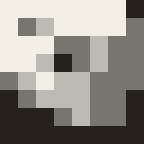
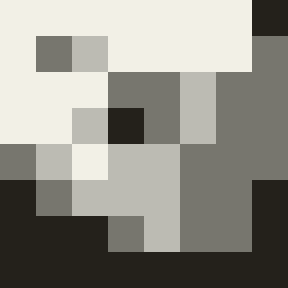

In [16]:
#| label: d9
lab.show_zoom()

**记录**：预测________；观察证据________；解释／修正________。

## T3a｜颜色表示的总结（56–57页）

同一种颜色采用查表编号与三个8位RGB通道时，为什么码长不同？引用四色码与RGB通道证据。

我的解释：________。

**教师操作与追问**

冻结版在56–57页先总结颜色表示。只收颜色表示证据并更新该枝，不在此处提问或讲出58页尚未发生的解码挑战。

## D10｜只有这些码字，能唯一画出图像吗？（Q18，58–60页）

把D3-read核对后的8个码字当作完整小图。四色码表与每像素2bit不变；每行从左到右，各行从上到下。先画一种排列，再与同桌比较。总像素数是否决定换行位置？

本题到58页才出现。

**教师操作与追问**

给定码字11 11 01 00 00 01 11 00，与58页相同。先独立画30–45秒，同桌读回。允许1×8、8×1、4×2、2×4，不把4×2当唯一标准答案。

In [17]:
#| label: d10
challenge_words = lab.encode(lab.quantize(lab.sample_blocks(16), 4)[5, 4:12], 2)
print(" ".join(challenge_words))
lab.show_palette(4, 2)

11 11 01 00 00 01 11 00


编号,代表色,RGB,码字
0,,"(36, 33, 27)",00
1,,"(119, 118, 110)",01
2,,"(188, 187, 179)",10
3,,"(242, 240, 230)",11


**记录**：预测________；观察证据________；解释／修正________。

## D10证据｜约定每行宽度后，再读回验证

先画好再运行。改变width、height，保持像素总数为8。检验按约定顺序读回后是否仍为原码字。

**教师操作与追问**

先运行4×2，再只改为2×4。两者读回都相同，说明码字与颜色表不足以唯一确定二维排列。恢复的是已量化记录，不会恢复采样和量化时失去的信息。尺寸不匹配会给出错误，用其诊断规则不一致。


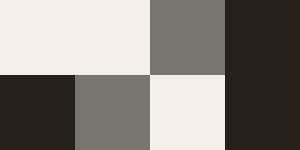

行,颜色编号（从左到右）
1,3 3 1 0
2,0 1 3 0


按行读回： 11 11 01 00 00 01 11 00
与输入码字相同： True


In [18]:
#| label: d10-reveal
width, height = 4, 2
restored = lab.show_decoded(challenge_words, width, height)
read_back = lab.encode(restored, 2)
print("按行读回：", " ".join(read_back))
print("与输入码字相同：", read_back == challenge_words)

**记录**：预测________；观察证据________；解释／修正________。

## T3b｜解码规则的总结（61–64页）

举出两种有效排列，说明相同码字怎样读回，并指出还需哪些解释规则。

我的规则与证据：________。

**教师操作与追问**

先收总结再回到61–62页更新解码枝；63–64页为定稿新增的整体图示。Notebook沿用熊猫和明确码表，不把示意图片中的排版或数字当作实验数据。

## D11｜连续量与有限位置有什么不同？（Q19–Q21，65–76页；85页附录）

温度从25到26，中间可否取25.5、25.51？请区分仪表显示精度与被测量。

下面用一条数学连续函数作示意：先取6个位置，但暂不限制数值等级。预测：取样会改变哪些位置有记录？密集曲线是绘图近似，不是无限精度的传感器记录。

**教师操作与追问**

与冻结版连续→离散的扩展一致。纵轴是模型单位，横轴是归一化位置/时间；它不是实际温度、声波或光强采集。这里只取有限位置，尚未量化；先让学生指出两类点。

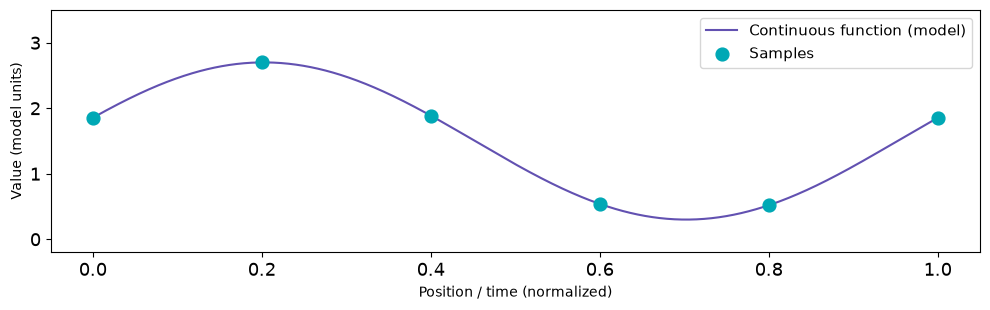

In [19]:
#| label: d11
sample_count = 6
lab.show_signal(sample_count, "sample")

**记录**：预测________；观察证据________；解释／修正________。

## D11证据｜位置不变，数值限制为四级

保留相同采样位置与样本值，数值限制为0、1、2、3四级，再写成2位码。先预测哪些样本会被映射到同一级。

**教师操作与追问**

取有限位置是采样，选择有限数值是量化，级别写成bit是编码。连续性不是“每一点有值”：整数阶梯函数也可每点有值而不连续。这里连续是数学模型的属性，不是凭屏幕线条光滑程度判断。该示意通常安排课后，不加进45分钟必做路径。

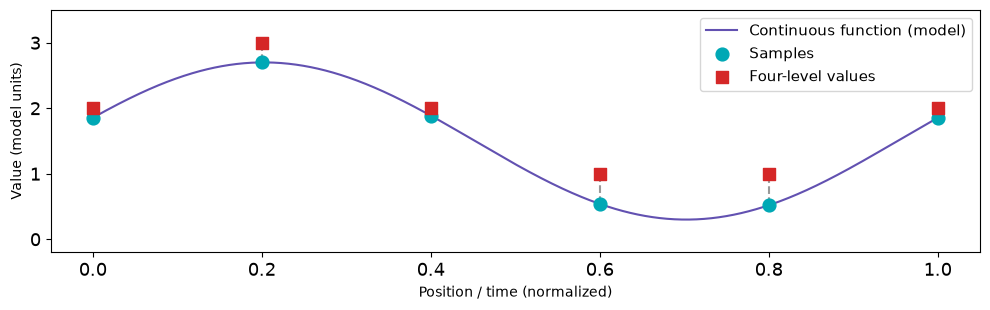

位置,样本值（近似）,量化级,2位码
0,1.85,2,10
0.2,2.7,3,11
0.4,1.89,2,10
0.6,0.54,1,01
0.8,0.52,1,01
1,1.85,2,10


In [20]:
#| label: d11-reveal
lab.show_signal(sample_count, "quantize")
positions, values, quantized_values = lab.signal_samples(sample_count)
lab.show_table(["位置", "样本值（近似）", "量化级", "2位码"],
    [(round(float(x), 2), round(float(y), 2), int(q), format(int(q), "02b"))
     for x, y, q in zip(positions, values, quantized_values)])

**记录**：预测________；观察证据________；解释／修正________。

## T4｜整个数字化过程的边界（76页总结后）

用已完成的实验连起采样、量化、编码、数据量、颜色表示与解码。请指出：放大显示和解码各自不能恢复什么？列一项已验证的事实与一项实验未模拟的物理过程。

我的完整总结：________。

**教师操作与追问**

先收学生总结。定稿76页为综合示意，未沿用旧77页生成稿的原生T4树。Notebook保留总结空间与六枝关系：采样→量化→编码；像素数与码长→理想数据量；码字＋尺寸／码表／顺序→已记录像素。明确该差异，不调用旧生成器替换冻结课件。

## D12｜32B预算下，哪些方案可行？（Q21-budget，78–79页）

需区分4色，固定长度编码，最多32B，只计像素码字。A=16×16/2bit；B=16×8/2bit；C=16×16/1bit；D=8×8/2bit。

先独立判断并写容量条件与数据量。不要只检查是否恰好32B。完成后再运行核对。

**教师操作与追问**

B、D。A超预算；C虽32B却只有2种状态；D无需用满预算。二项都要满足。本题相同取景范围，并未证明某个有效方案在所有视觉目标上最佳。

In [21]:
#| label: d12
plans = {"A": (16, 16, 2), "B": (16, 8, 2), "C": (16, 16, 1), "D": (8, 8, 2)}
lab.show_table(["方案", "容量", "像素B", "容量足够", "数据量达标", "两项都满足"],
    [(name, result["capacity"], result["packed_B"], result["capacity_ok"], result["size_ok"], result["valid"])
     for name, parameters in plans.items()
     for result in [lab.check_budget(*parameters, colors=4, budget_B=32)]])

方案,容量,像素B,容量足够,数据量达标,两项都满足
A,4,64,是,否,否
B,4,32,是,是,是
C,2,32,否,是,否
D,4,16,是,是,是


**记录**：预测________；观察证据________；解释／修正________。

## E1｜独立退出题，先交答再核对（80–82页）

12×10像素，要区分5种颜色；最短固定长度码，只计未压缩像素码字，最多50B。

1. 至少几bit？写容量不等式。
2. 数据量多少B？写带单位的算式。
3. 是否满足预算？
4. 这个结果能当作完整PNG文件大小吗？写一句理由。

先提交四项答案，本题运行单元不自动填写答案。教师收齐后才把submitted改为True；文件理由需人工核对。

**教师操作与追问**

独立60秒，收齐后再揭示PPTX81–82页。答案3bit（4<5≤8）、45B、满足、不是完整PNG长度。四项至少三项正确且容量必须正确。漏除8回指bit/B；误说PNG为3bit索引时说明教学模型与PNG1/2/4/8索引位数不同。不要把该教师段落投影。

In [22]:
#| label: e1
answer_bits = None
answer_bytes = None
answer_fits = None
answer_file_reason = ""
submitted = False
feedback = lab.exit_feedback(answer_bits, answer_bytes, answer_fits, answer_file_reason, submitted)
lab.show_table(["核对项目", "反馈"], list(feedback.items()))

核对项目,反馈
已提交,否
提示,先独立交答；收齐后再把submitted改为True核对。


## 课后迁移｜换参数时仍要说明边界（83页）

1. 6种颜色的最短固定码长是多少？写不等式。
2. 800×600、24位RGB的未压缩像素数据量是多少B？
3. 把宽和高都放大2倍，就获得新采集的细节了吗？

用独立书面回答。若用代码核对，先交保留算式的答案。

**教师操作与追问**

1.3bit；2.1440000B；3.没有，插值或重复显示不等于真实采集更多信息。遇到“像素数量增加所以必然细节增加”，让学生回看D3与D9的输入数据是否改变。84页为附录分隔，85页连续→离散示意为扩展，不新增必做计算。
